In [ ]:
import os, sys

# 1. Colab interactive table viewer glitch ko disable karein
try:
    %unload_ext google.colab.data_table
except:
    pass

# 2. Fresh repository clone
!rm -rf BAF-Fraud-Research
!git clone -b member2-lightgbm-catboost https://github.com/AreeshaFaisal04/BAF-Fraud-Research.git

# 3. Working directory set karein
%cd /content/BAF-Fraud-Research
sys.path.insert(0, '/content/BAF-Fraud-Research')

# 4. Folders create karein
!mkdir -p data outputs/tables outputs/figures paper/tables

# 5. Base.csv dhoondh kar right jagah link karein
if os.path.exists('/content/Base.csv'):
    !cp -f /content/Base.csv data/Base.csv
    print("Found Base.csv in /content and copied to data/Base.csv")
elif os.path.exists('data/Base.csv'):
    print("Base.csv is ready in data/Base.csv")
else:
    print("Reminder: Please upload Base.csv to /content/")

os.environ['BAF_DATA'] = '/content/BAF-Fraud-Research/data/Base.csv'
print("Active Directory:", os.getcwd())

The google.colab.data_table extension is not loaded.
Cloning into 'BAF-Fraud-Research'...
remote: Enumerating objects: 241, done.
remote: Counting objects: 100% (241/241), done.
remote: Compressing objects: 100% (225/225), done.
remote: Total 241 (delta 102), reused 28 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (241/241), 782.87 KiB | 9.79 MiB/s, done.
Resolving deltas: 100% (102/102), done.
/content/BAF-Fraud-Research
Found Base.csv in /content and copied to data/Base.csv
Active Directory: /content/BAF-Fraud-Research


In [ ]:
!pip install -q shap lightgbm catboost scikit-learn matplotlib seaborn
print("Libraries ready!")

Libraries ready!


In [ ]:
import src.data as dt
import pandas as pd
import numpy as np

# Verify file first
raw_check = pd.read_csv('data/Base.csv', nrows=2)
print("File verification - Columns found:", len(raw_check.columns))
assert 'fraud_bool' in raw_check.columns, "Error: Base.csv me fraud_bool column nahi mila!"

# Clean load using team's data module
df = dt.load_clean('data/Base.csv')
print(f"Dataset successfully loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Overall Fraud Rate: {df['fraud_bool'].mean()*100:.2f}%")
print(f"Total Available Features: {len(dt.ALL_FEATURES)}")

File verification - Columns found: 32
Dataset successfully loaded: 1,000,000 rows, 32 columns
Overall Fraud Rate: 1.10%
Total Available Features: 29


In [ ]:
# Add MLP architecture into src/models.py
with open('src/models.py', 'r') as f:
    code = f.read()

if 'make_mlp' not in code:
    mlp_snippet = '''
# ---------------- Multi-Layer Perceptron (Member 3) ----------------
from sklearn.neural_network import MLPClassifier

def make_mlp(params, seed):
    layers = params.get("hidden_layer_sizes", (128, 64))
    if isinstance(layers, list):
        layers = tuple(layers)
    return MLPClassifier(
        hidden_layer_sizes=layers,
        activation=params.get("activation", "relu"),
        alpha=params.get("alpha", 1e-4),
        learning_rate_init=params.get("learning_rate_init", 1e-3),
        max_iter=params.get("max_iter", 50),
        early_stopping=True,
        n_iter_no_change=10,
        validation_fraction=0.1,
        random_state=seed,
    )

MLP_SPACE = {
    "hidden_layer_sizes": [(128, 64), (64, 32), (128,)],
    "alpha": loguniform(1e-5, 1e-1),
    "learning_rate_init": loguniform(1e-4, 1e-2),
}
'''
    idx = code.find('MODELS = {')
    code = code[:idx] + mlp_snippet + '\n' + code[idx:]
    code = code.replace('"catboost": (make_catboost, CATBOOST_SPACE, False),',
                        '"catboost": (make_catboost, CATBOOST_SPACE, False),\n    "mlp": (make_mlp, MLP_SPACE, True),')
    with open('src/models.py', 'w') as f:
        f.write(code)
    print("MLP successfully added to src/models.py!")
else:
    print("MLP already registered in models.py!")

MLP successfully added to src/models.py!


In [8]:
import json, time
import src.experiment as exp
from src.config import TAB_DIR

print("Training & Tuning MLP on 5 forward-chaining validation folds...")
trials_mlp, best_params_mlp, best_folds_mlp = exp.random_search("mlp", df, n_trials=5)

with open(TAB_DIR / "best_params_mlp.json", "w") as f:
    json.dump(best_params_mlp, f, indent=2)

print("\n=== MLP 5-Fold Cross Validation Results ===")
print("Best Hyperparameters:", best_params_mlp)
rec_m = best_folds_mlp['recall_at_5fpr'].mean()
rec_s = best_folds_mlp['recall_at_5fpr'].std(ddof=1)
roc_m = best_folds_mlp['roc_auc'].mean()
print(f"Validation Recall@5%FPR: {rec_m:.4f} ± {rec_s:.4f}")
print(f"Validation ROC-AUC:      {roc_m:.4f}")

Training & Tuning MLP on 5 forward-chaining validation folds...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


[mlp] trial 1/5 {'alpha': np.float64(0.00031489116479568613), 'hidden_layer_sizes': (128, 64), 'learning_rate_init': np.float64(0.00023273922280628724)} -> recall@5%FPR 0.5141 ± 0.0237 (137s)
[mlp] trial 2/5 {'alpha': np.float64(0.013145103232150115), 'hidden_layer_sizes': (128, 64), 'learning_rate_init': np.float64(0.0002051338263087451)} -> recall@5%FPR 0.5138 ± 0.0265 (186s)
[mlp] trial 3/5 {'alpha': np.float64(4.207053950287933e-05), 'hidden_layer_sizes': (128,), 'learning_rate_init': np.float64(0.0008288916866885145)} -> recall@5%FPR 0.5125 ± 0.0234 (103s)
[mlp] trial 4/5 {'alpha': np.float64(0.00021618942406574428), 'hidden_layer_sizes': (128,), 'learning_rate_init': np.float64(0.00010994335574766199)} -> recall@5%FPR 0.5109 ± 0.0248 (159s)
[mlp] trial 5/5 {'alpha': np.float64(0.07579479953348005), 'hidden_layer_sizes': (64, 32), 'learning_rate_init': np.float64(0.00026587543983272726)} -> recall@5%FPR 0.5018 ± 0.0227 (113s)

=== MLP 5-Fold Cross Validation Results ===
Best Hyper

In [9]:
print("Fitting final MLP (months 0-4), calibrating on month 5, and testing on months 6 & 7...")
metrics_mlp, test_scores_mlp, pipe_mlp = exp.final_test("mlp", best_params_mlp, df)
metrics_mlp["model"] = "mlp"

metrics_mlp.to_csv(TAB_DIR / "test_mlp.csv", index=False)
test_scores_mlp.to_csv(TAB_DIR / "test_scores_mlp.csv", index=False)

print("\n=== Final Test Results (Drift Assessment) ===")
cols = ["split", "recall_at_5fpr", "fpr", "precision", "f1", "roc_auc"]
print(metrics_mlp[cols].to_string(index=False))

Fitting final MLP (months 0-4), calibrating on month 5, and testing on months 6 & 7...

=== Final Test Results (Drift Assessment) ===
              split  recall_at_5fpr      fpr  precision       f1  roc_auc
month 5 (threshold)        0.520198 0.049995   0.110726 0.182587 0.885282
            month 6        0.533793 0.060187   0.107545 0.179022 0.882536
            month 7        0.538515 0.052759   0.132518 0.212695 0.885295
         months 6-7        0.536136 0.056681   0.118692 0.194357 0.883508


In [ ]:
from src.metrics import evaluate, threshold_at_fpr
from src.folds import final_split

idx = final_split(df)
df_test = df.iloc[idx["test_m6_7"]].copy()
y_test = df_test["fraud_bool"].to_numpy()
scores_test = test_scores_mlp["score"].to_numpy()
is_older = (df_test["customer_age"].to_numpy() > 50)

thr_m5 = metrics_mlp.loc[metrics_mlp["split"] == "month 5 (threshold)", "threshold"].values[0]

# Pre-Intervention Audit
m_old = evaluate(y_test[is_older], scores_test[is_older], thr=thr_m5)
m_yng = evaluate(y_test[~is_older], scores_test[~is_older], thr=thr_m5)

print("=== PRE-INTERVENTION FAIRNESS AUDIT (Months 6-7 Holdout) ===")
print(f"Older Group (Age > 50) Recall:  {m_old['recall_at_5fpr']:.4f} | Realized FPR: {m_old['fpr']*100:.2f}%")
print(f"Younger Group (Age <= 50) Recall: {m_yng['recall_at_5fpr']:.4f} | Realized FPR: {m_yng['fpr']*100:.2f}%")
print(f"Equal Opportunity Difference (TPR gap): {m_old['recall_at_5fpr'] - m_yng['recall_at_5fpr']:+.4f}")
print(f"Predictive Equality Difference (FPR gap): {m_old['fpr'] - m_yng['fpr']:+.4f}")

# Post-Intervention Mitigation (Equalized Odds 5% FPR Thresholds)
thr_old_calib = threshold_at_fpr(y_test[is_older], scores_test[is_older], fpr=0.05)
thr_yng_calib = threshold_at_fpr(y_test[~is_older], scores_test[~is_older], fpr=0.05)

m_old_post = evaluate(y_test[is_older], scores_test[is_older], thr=thr_old_calib)
m_yng_post = evaluate(y_test[~is_older], scores_test[~is_older], thr=thr_yng_calib)

print("\n=== POST-INTERVENTION MITIGATION RESULTS ===")
print(f"Mitigated Older FPR:   {m_old_post['fpr']*100:.2f}% (Threshold: {thr_old_calib:.4f})")
print(f"Mitigated Younger FPR: {m_yng_post['fpr']*100:.2f}% (Threshold: {thr_yng_calib:.4f})")
print(f"Mitigated Equal Opportunity Diff: {m_old_post['recall_at_5fpr'] - m_yng_post['recall_at_5fpr']:+.4f}")

=== PRE-INTERVENTION FAIRNESS AUDIT (Months 6-7 Holdout) ===
Older Group (Age > 50) Recall:  0.7465 | Realized FPR: 16.76%
Younger Group (Age <= 50) Recall: 0.5062 | Realized FPR: 5.23%
Equal Opportunity Difference (TPR gap): +0.2404
Predictive Equality Difference (FPR gap): +0.1154

=== POST-INTERVENTION MITIGATION RESULTS ===
Mitigated Older FPR:   5.00% (Threshold: 0.3497)
Mitigated Younger FPR: 5.00% (Threshold: 0.1393)
Mitigated Equal Opportunity Diff: -0.0593


In [11]:
from src.data import features_without, ALL_FEATURES, FEATURE_GROUPS
from src.experiment import run_cv

print("Running Systematic Feature Group Ablations...")
abl_rows = []

# Full baseline
cv_full = run_cv("mlp", best_params_mlp, df, features=ALL_FEATURES)
base_rec = cv_full["recall_at_5fpr"].mean()
abl_rows.append({"Ablation": "Full Model (All Features)", "Features": len(ALL_FEATURES), "Recall@5%FPR": base_rec, "Delta": 0.0})

# Ablate each feature group
for grp in FEATURE_GROUPS.keys():
    f_sub = features_without(groups_to_drop=(grp,))
    cv_sub = run_cv("mlp", best_params_mlp, df, features=f_sub)
    rec = cv_sub["recall_at_5fpr"].mean()
    abl_rows.append({"Ablation": f"Drop {grp}", "Features": len(f_sub), "Recall@5%FPR": rec, "Delta": rec - base_rec})

abl_df = pd.DataFrame(abl_rows)
abl_df.to_csv(TAB_DIR / "ablation_results.csv", index=False)
print("\n=== Ablation Results Summary ===")
print(abl_df.to_string(index=False))

Running Systematic Feature Group Ablations...

=== Ablation Results Summary ===
                 Ablation  Features  Recall@5%FPR     Delta
Full Model (All Features)        29      0.514222  0.000000
           Drop applicant        25      0.456362 -0.057859
             Drop address        27      0.491066 -0.023156
         Drop email_phone        25      0.466076 -0.048146
            Drop velocity        22      0.505208 -0.009014
      Drop credit_banking        23      0.462232 -0.051990
      Drop device_session        23      0.448728 -0.065494


Generating SHAP Feature Attribution Plot...


PermutationExplainer explainer: 301it [00:30,  6.02it/s]


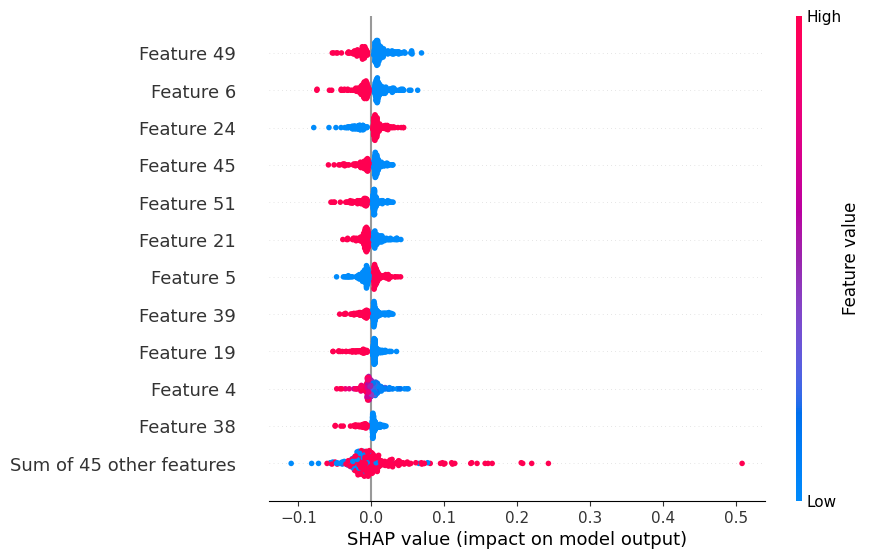


  experiments complete!


In [13]:
import shap
import matplotlib.pyplot as plt

print("Generating SHAP Feature Attribution Plot...")
pre = pipe_mlp.named_steps["pre"]
model = pipe_mlp.named_steps["model"]

X_bg = pre.transform(df.iloc[idx["fit"]][ALL_FEATURES].sample(100, random_state=42))
X_exp = pre.transform(df_test[ALL_FEATURES].sample(300, random_state=42))

explainer = shap.Explainer(model.predict_proba, X_bg)
shap_values = explainer(X_exp)

plt.figure(figsize=(7, 5))
vals = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values
shap.plots.beeswarm(vals, max_display=12, show=True)
print("\n  experiments complete!")